# CityPulse Data Analytics Competition — Complete Analysis
Reproducible analysis covering Rounds 1–5 using `dashboard.py` and raw CSV files in `data/`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import dashboard

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

traffic, sensors, weather, incidents = dashboard.load_data(Path("data"))
print("Loaded row counts:", {
    "traffic": len(traffic),
    "sensors": len(sensors),
    "weather": len(weather),
    "incidents": len(incidents),
})


Loaded row counts: {'traffic': 13392, 'sensors': 18, 'weather': 4446, 'incidents': 130}


## Round 1 — Data Integration & Integrity Checks
- Left joins preserve all 13,392 traffic observations.
- `validate=` enforces key cardinality (`many_to_one` for sensors & weather, `one_to_one` for incidents).
- Unmatched weather rows and orphan incident sensor IDs are explicitly reported.


In [2]:
integrated, reports = dashboard.integrate_data(traffic, sensors, weather, incidents, verbose=True)
print("\nKey uniqueness checks:", reports["key_uniqueness"])
print("\nOrphan incidents referencing unknown sensor IDs:")
display(reports["unknown_sensor_incidents"])


[Merge 1: traffic + sensors]   before=13392, after=13392, matches={'both': 13392, 'left_only': 0, 'right_only': 0}
[Merge 2: + weather]           before=13392, after=13392, matches={'both': 13338, 'left_only': 54, 'right_only': 0} (18 missing district-hours)
[Merge 3: + incidents]         before=13392, after=13392, matches={'left_only': 13265, 'both': 127, 'right_only': 0}
[Integrity] Orphan incidents with unknown sensor_id: 3 -> ['S-099', 'S-098', 'S-097']

Key uniqueness checks: {'traffic_(timestamp,sensor_id)': True, 'sensors_sensor_id': True, 'weather_(timestamp,district)': True, 'incidents_incident_id': True, 'incidents_(timestamp,sensor_id)': True}

Orphan incidents referencing unknown sensor IDs:


,incident_id,timestamp,sensor_id,incident_type,severity,duration_min,lanes_blocked
127,INC-ORPHAN-001,2026-10-22 08:00:00,S-099,debris_on_road,moderate,25,1
128,INC-ORPHAN-002,2026-11-03 17:00:00,S-098,vehicle_breakdown,low,18,0
129,INC-ORPHAN-003,2026-11-10 11:00:00,S-097,minor_collision,high,40,1


**Round 1 Answers:**
1. **Traffic observations before & after integration:** 13,392 before and 13,392 after (no row loss or explosion).
2. **Weather rows failing to match:** 54 traffic rows (18 distinct `(timestamp, district)` hours missing from `weather.csv`; 4,446 present vs 4,464 expected).
3. **Incidents referring to unknown sensors:** 3 orphan incidents (`INC-ORPHAN-001` → `S-099`, `INC-ORPHAN-002` → `S-098`, `INC-ORPHAN-003` → `S-097`).
4. **Effect of duplicate right-hand merge keys:** Causes row explosion (Cartesian multiplication of matched left rows), inflating vehicle totals and distorting averages; prevented by `validate=`.


## Round 2 — Traffic Hotspots (District & Road Rankings)
Severity mapping: `low=1, moderate=2, high=3, critical=4`.
Peak hours defined from hourly profile: `07:00–09:00` and `16:00–18:00`.


In [3]:
hotspots = dashboard.traffic_hotspots(integrated)
print("=== District Ranking (sorted by avg vehicles) ===")
display(hotspots["by_district"].round(2))

print("=== Road Ranking (Top 10 by avg vehicles) ===")
display(hotspots["by_road"].head(10).round(2))

print("=== Top 5 Roads by Average Incident Severity ===")
display(hotspots["highest_severity_roads"][["sensor_id", "road_name", "district", "incident_count", "avg_severity"]].head(5).round(2))


=== District Ranking (sorted by avg vehicles) ===


,district,avg_vehicles,total_vehicles,avg_speed_kmh,incident_count,avg_severity,observations,off_peak_avg_vehicles,peak_avg_vehicles,peak_vs_off_peak_diff
0,Central,74.57,166435,42.52,16,2.12,2232,55.43,131.97,76.53
1,Riverside,64.13,143138,36.32,31,2.10,2232,47.93,112.74,64.81
2,University,61.50,137259,36.53,16,1.88,2232,45.88,108.35,62.47
3,Industrial,56.39,125871,39.09,26,2.23,2232,42.08,99.34,57.26
4,Airport,52.48,117137,42.26,18,2.00,2232,39.01,92.89,53.88
5,Old Town,42.84,95617,30.39,20,2.10,2232,31.82,75.90,44.08


=== Road Ranking (Top 10 by avg vehicles) ===


,sensor_id,road_name,district,road_type,speed_limit_kmh,avg_vehicles,total_vehicles,avg_speed_kmh,incident_count,avg_severity
0,S-003,Central Boulevard,Central,arterial,60,74.71,55586,45.71,5,1.80
1,S-001,Main Avenue,Central,arterial,60,74.50,55430,45.87,7,2.43
2,S-002,Market Street,Central,collector,50,74.49,55419,35.97,4,2.00
3,S-004,Bridge Road,Riverside,arterial,60,64.29,47829,45.33,11,1.64
4,S-005,Riverbank Avenue,Riverside,collector,50,64.07,47671,35.65,8,2.50
5,S-006,Quay Street,Riverside,local,40,64.03,47638,27.99,12,2.25
6,S-013,Campus Drive,University,collector,50,61.52,45774,35.99,6,2.17
7,S-014,Science Avenue,University,arterial,60,61.52,45768,45.55,6,1.67
8,S-015,Library Road,University,local,40,61.45,45717,28.04,4,1.75
9,S-010,Factory Road,Industrial,arterial,60,56.63,42133,45.48,10,2.20


=== Top 5 Roads by Average Incident Severity ===


,sensor_id,road_name,district,incident_count,avg_severity
0,S-009,Museum Road,Old Town,9,2.78
1,S-005,Riverbank Avenue,Riverside,8,2.50
2,S-001,Main Avenue,Central,7,2.43
3,S-011,Logistics Avenue,Industrial,7,2.29
4,S-006,Quay Street,Riverside,12,2.25


## Round 3 — Time Series Investigation
Daily resampling, 3-day moving average, period-over-period changes, busiest hour, slowest day, and weekday vs weekend comparison.


In [4]:
ts = dashboard.time_series_report(integrated)

print("=== Busiest Hours (Top 5) ===")
display(ts["by_hour"].sort_values("total_vehicles", ascending=False).head(5).round(2))

print("=== Slowest Days (Top 5) ===")
display(ts["daily_trend"].sort_values("daily_avg_speed_kmh", ascending=True).head(5).round(2))

print("=== Weekday vs Weekend ===")
display(ts["weekday_vs_weekend"].round(2))

print("=== Largest Daily Volume Changes (%) ===")
dt = ts["daily_trend"]
display(dt.loc[[dt["vehicles_pct_change"].idxmax(), dt["vehicles_pct_change"].idxmin()],
               ["timestamp", "day_name", "daily_vehicles", "vehicles_diff", "vehicles_pct_change"]].round(2))


=== Busiest Hours (Top 5) ===


,hour,total_vehicles,avg_vehicles_per_sensor,avg_speed_kmh,incident_count
17,17,59597,106.80,34.18,7
18,18,59501,106.63,34.10,5
16,16,59281,106.24,34.19,4
9,9,56204,100.72,34.21,5
7,7,56039,100.43,34.18,12


=== Slowest Days (Top 5) ===


C:\Users\Krystian K\AppData\Local\Temp\ipykernel_12576\4041561866.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ts["daily_trend"].sort_values("daily_avg_speed_kmh", ascending=True).head(5).round(2))


,timestamp,daily_vehicles,daily_avg_speed_kmh,daily_incidents,vehicles_ma3,speed_ma3,vehicles_diff,vehicles_pct_change,speed_diff,speed_pct_change,day_name
28,2026-11-12,27518,37.40,4,27639.67,37.77,-43.0,-0.16,-0.67,-1.76,Thursday
18,2026-11-02,27572,37.67,2,22216.33,37.80,8002.0,40.89,-0.23,-0.60,Monday
8,2026-10-23,27897,37.70,3,27759.33,37.78,363.0,1.32,-0.01,-0.03,Friday
15,2026-10-30,27658,37.71,3,27849.00,37.84,-361.0,-1.29,-0.23,-0.60,Friday
7,2026-10-22,27534,37.71,5,27646.67,37.84,-313.0,-1.12,-0.23,-0.61,Thursday


=== Weekday vs Weekend ===


,day_type,avg_vehicles_per_sensor,avg_speed_kmh,total_incidents,observations
0,Weekday,64.21,37.85,91,9504
1,Weekend,45.07,37.86,36,3888


=== Largest Daily Volume Changes (%) ===


C:\Users\Krystian K\AppData\Local\Temp\ipykernel_12576\4041561866.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ["timestamp", "day_name", "daily_vehicles", "vehicles_diff", "vehicles_pct_change"]].round(2))


,timestamp,day_name,daily_vehicles,vehicles_diff,vehicles_pct_change
25,2026-11-09,Monday,27951,8659.0,44.88
2,2026-10-17,Saturday,19306,-8458.0,-30.46


## Round 4 — The Traffic Mystery (12 November 2026)
Fair baseline: same hours (`07:00–12:00`) in Riverside on 6 nearby non-event weekdays (`Nov 5, 6, 9, 10, 11, 13`).


In [5]:
mystery = dashboard.investigate_mystery(integrated)
print(f"Affected District: {mystery['affected_district']}")
print(f"Anomaly Window:    {mystery['affected_window']}")
print(f"Event Speed:       {mystery['overall_event_speed_kmh']} km/h vs Baseline {mystery['overall_baseline_speed_kmh']} km/h "
      f"(Drop: {mystery['overall_speed_drop_pct']}%)")

print("\n=== Affected Roads in Riverside (07:00-12:00) ===")
display(mystery["road_impact"].round(2))

print("\n=== Incidents in Window ===")
display(mystery["window_incidents"])

print("\n=== Weather in Window ===")
display(mystery["window_weather"])


Affected District: Riverside
Anomaly Window:    2026-11-12 07:00-12:59
Event Speed:       19.72 km/h vs Baseline 34.94 km/h (Drop: 43.56%)

=== Affected Roads in Riverside (07:00-12:00) ===


,sensor_id,road_name,road_type,event_speed_kmh,event_vehicles,incidents,baseline_speed_kmh,baseline_vehicles,speed_drop_pct,vehicle_drop_pct
0,S-004,Bridge Road,arterial,24.37,77.00,1,43.72,103.39,44.27,25.52
1,S-006,Quay Street,local,15.35,78.33,1,27.26,100.75,43.70,22.25
2,S-005,Riverbank Avenue,collector,19.43,79.83,1,33.83,100.14,42.55,20.28



=== Incidents in Window ===


,timestamp,sensor_id,road_name,incident_id,incident_type,severity,duration_min,lanes_blocked
0,2026-11-12 07:00:00,S-004,Bridge Road,INC-MYST-001,multi_vehicle_collision,critical,110.0,2.0
1,2026-11-12 08:00:00,S-005,Riverbank Avenue,INC-MYST-002,road_closure,high,95.0,1.0
2,2026-11-12 09:00:00,S-006,Quay Street,INC-MYST-003,traffic_signal_failure,high,73.0,0.0



=== Weather in Window ===


,timestamp,temperature_c,rainfall_mm,wind_speed_kmh,weather_condition
0,2026-11-12 07:00:00,6.9,0.0,12.0,Clear
1,2026-11-12 08:00:00,3.8,0.0,12.0,Clear
2,2026-11-12 09:00:00,5.9,0.0,12.0,Clear
3,2026-11-12 10:00:00,4.3,0.0,12.0,Clear
4,2026-11-12 11:00:00,3.5,0.0,12.0,Clear
5,2026-11-12 12:00:00,5.8,0.0,12.0,Clear


## Round 5 — Final Dashboard & Visualizations


=== Incident Summary ===


,incident_type,severity,incident_count,avg_duration_min,avg_lanes_blocked
0,debris_on_road,moderate,12,51.58,0.58
1,vehicle_breakdown,moderate,10,47.80,0.40
2,minor_collision,moderate,9,52.78,0.44
3,minor_collision,low,9,38.89,0.78
4,road_closure,moderate,9,44.11,0.78
5,debris_on_road,low,9,45.67,0.44
6,vehicle_breakdown,high,8,38.38,0.62
7,traffic_signal_failure,moderate,8,40.00,0.50
8,minor_collision,high,8,54.62,0.38
9,vehicle_breakdown,low,8,40.88,0.25


=== Weather Comparison ===


,weather_condition,observations,avg_vehicles,avg_speed_kmh,incident_count
0,Rain,1260,60.10,34.74,11
1,Clear,10914,58.83,38.15,104
2,Drizzle,594,54.30,38.30,5
3,Windy,570,57.37,38.80,7


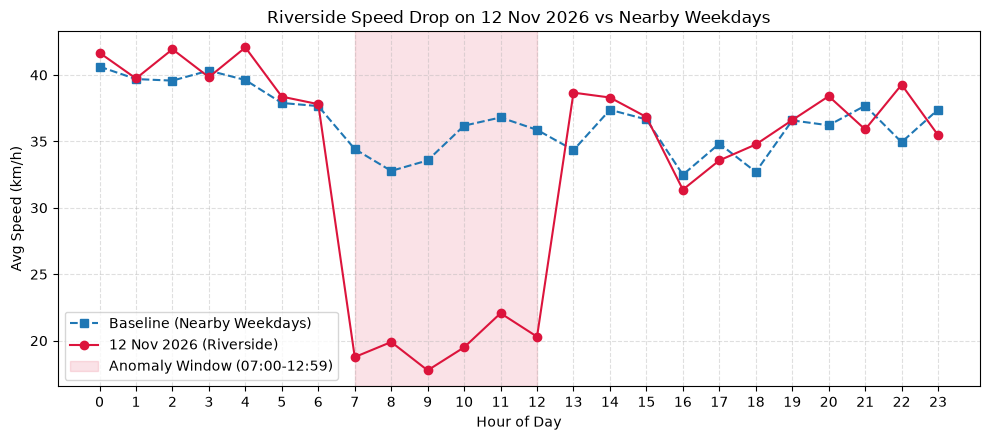

In [6]:
dash = dashboard.city_dashboard(traffic, sensors, weather, incidents)
print("=== Incident Summary ===")
display(dash["incident_summary"].round(2))

print("=== Weather Comparison ===")
display(dash["weather_comparison"].round(2))

# Plot Riverside Mystery
hc = mystery["hourly_comparison"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hc["hour"], hc["baseline_speed_kmh"], "--s", label="Baseline (Nearby Weekdays)")
ax.plot(hc["hour"], hc["event_speed_kmh"], "-o", color="crimson", label="12 Nov 2026 (Riverside)")
ax.axvspan(7, 12, color="crimson", alpha=0.12, label="Anomaly Window (07:00-12:59)")
ax.set_title("Riverside Speed Drop on 12 Nov 2026 vs Nearby Weekdays")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Avg Speed (km/h)")
ax.set_xticks(range(0, 24))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()
